# Order and density of a virtual swarm modulate directional alignment in marching locusts

Juvenile desert locusts (*Schistocerca gregaria*) align their heading with the
direction of neighbor motion, a core ingredient of marching behavior. In
virtual-reality experiments (Sayin et al., 2025), focal locusts walked on a
motion-compensating spherical treadmill surrounded by a panoramic projection
of moving **virtual conspecifics**. The virtual swarm was defined by two
continuous stimulus parameters:

- **order** — the coherence of the virtual motion, 0 = disordered to 1 =
  perfectly aligned (six levels: 0, 0.2, 0.4, 0.6, 0.8, 1.0);
- **density** — the number of virtual locusts per m$^2$ (six levels: 1, 4, 8,
  16, 32, 64).

The biological question: is the focal locust's directional alignment driven
primarily by the directional structure of neighbor motion (order), or does the
number of neighbors (density) matter comparably?

This notebook re-analyzes one such dataset with **von Mises GLMs** on
re-discretized step headings: it builds the step-level design, screens
candidate fixed-effect specifications with PSIS-LOO at the level of
individuals, fits the final random-intercept hierarchical model in `bambi`
with `unwrap`'s circular link functions, and validates it with the
**alignment** predictive statistic,

$$\mathcal{A}(\mathbf{x}) \;=\; R(\kappa(\mathbf{x}))\,\cos\bigl(\mu(\mathbf{x})\bigr),
\qquad R(\kappa)=I_1(\kappa)/I_0(\kappa),$$

measured at the virtual march direction ($0^\circ$ — perfect alignment is
$\mathcal{A}=1$; no preferred direction is $\mathcal{A}=0$).

> **Note on data availability:** the raw per-animal tracking parts
> (``density_order/XY_part_*.parquet``, ~870 MB in
> [jgraving/unwrap-data](https://github.com/jgraving/unwrap-data)) are not
> shipped with this repository and are downloaded on first use by
> `load_density_order()` (first call shows a progress meter; later runs
> reuse the cached clone with no download). The rediscretization below
> runs in-notebook, so the notebook is fully self-contained after that
> initial fetch.

In [1]:
%matplotlib inline
from importlib.metadata import version
from math import pi
import os
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import arviz as az
import bambi as bmb
import pymc as pm

import unwrap
from unwrap.circular import circular_summary
from unwrap.datasets import load_density_order
from unwrap.link import inverse_softplus
from unwrap.link.bambi import circular_modulo, softplus
from pymc.distributions.transforms import LogExpM1 as Softplus

# The preprocessing, post-hoc and figure code lives in sibling scripts next
# to this notebook (locust_density_preprocess.py, locust_density_posthoc.py,
# locust_density_plots.py); make them importable regardless of the kernel's
# working directory (the kernel may run from notebooks/ or from the
# repository root).
sys.path.insert(0, os.path.join(os.path.dirname(os.path.dirname(unwrap.__file__)), "notebooks"))

from locust_density_preprocess import rediscretize_density_order
import locust_density_posthoc as posthoc
import locust_density_plots as plots

plots.set_style()

SEED = 123
{package: version(package) for package in (
    "unwrap", "pymc", "arviz",
    "numpy", "pandas", "scipy", "matplotlib",
)}

Figures will be saved to: figures/locust


{'unwrap': '0.0.1',
 'pymc': '6.3.2',
 'arviz': '1.3.0',
 'numpy': '2.4.6',
 'pandas': '3.1.0',
 'scipy': '1.18.1',
 'matplotlib': '3.10.9'}

## Data loading

The first code cell pulls the raw per-animal tracking parts from
[jgraving/unwrap-data](https://github.com/jgraving/unwrap-data) with
`load_density_order()` (one-time ~870 MB download with a progress bar; later
runs reuse the cached clone). The rediscretization code cell next samples each
raw trajectory to equal arc length — one step every **6 body lengths** — and
builds the step-level ``merged_df`` the models are fit to. Columns of
``merged_df``:

- `fname` — raw individual identifier (one raw trajectory = one animal);
- `order`, `density` — the virtual-swarm stimulus condition, constant per
  animal (each animal experienced exactly one of the
  $6 \times 6 = 36$ order–density combinations);
- `X`, `Y` — step position on the arena plane (meters);
- `dX`, `dY` — the step's displacement;
- `direction` — step heading $\theta = \operatorname{atan2}(dY, dX)$ in
  radians, with $0$ the global march direction;
- `animal_id` — zero-based id, unique per (order, density, `fname`).

In [2]:
# The raw per-animal tracking parts (one-time ~870 MB download with a
# progress bar on first use; later runs reuse the cached clone). `data_root`
# may be None (default), a local path to an existing unwrap-data checkout,
# or a path to a directory that already contains the parquet parts.
dfXY = load_density_order()

In [3]:
np.sort(dfXY["density"].unique()), np.sort(dfXY["order"].unique())

(array([ 1,  4,  8, 16, 32, 64]), array([0. , 0.2, 0.4, 0.6, 0.8, 1. ]))

In [4]:
dfXY["fname"].unique().shape

(470,)

In [5]:
dfXY["loss"].min(), dfXY["loss"].max()

(np.float64(0.0008416736806140523), np.float64(0.9999749997916649))

## Stimulus levels and animals

The observed stimulus levels match the experimental design —
$\mathrm{density}\in\{1,4,8,16,32,64\}\ \mathrm{m}^{-2}$ and
$\mathrm{order}\in\{0,0.2,0.4,0.6,0.8,1.0\}$ — and the file set covers the
raw individual tracks (470); after trajectory re-discretization, $N = 440$
animals enter modelling.

In [6]:
# Rediscretize every raw trajectory to equal arc length (one step every 6
# body lengths) and build the step-level merged_df; the per-animal pipeline
# lives in notebooks/locust_density_preprocess.py on top of the shared arc
# length primitives of unwrap.preprocess.
merged_df = rediscretize_density_order(dfXY)

In [7]:
merged_df["animal_id"].nunique()

440

## How the step data were produced

Raw arena positions were resampled at equal arc length: each trajectory was
densely interpolated, then sampled at successive points spaced by the
**step length of 6 body lengths** (chosen by a lag-1 circular-autocorrelation
screen over $\ell \in \{1,\dots,10\}$ body lengths, to obtain
approximately independent steps). Each consecutive pair of resampled
positions defines a step heading
$\theta_t = \operatorname{atan2}(dY_t, dX_t)$.

Some animals were dropped during rediscretization (too short, or with
tracking gaps), so 440 animals enter modelling. The rediscretization runs in the code cells of this notebook
(dense interpolation, then equal-arc-length stepping); it reproduces, for any
raw parts, the same steps the data clone publishes are derived from.

Sorted orders: [0.0, 0.2, 0.4, 0.6, 0.8, 1.0]
Sorted densities: [1.0, 4.0, 8.0, 16.0, 32.0, 64.0]


Saved figure to: figures/locust/trajectories_order_by_density_grid.pdf


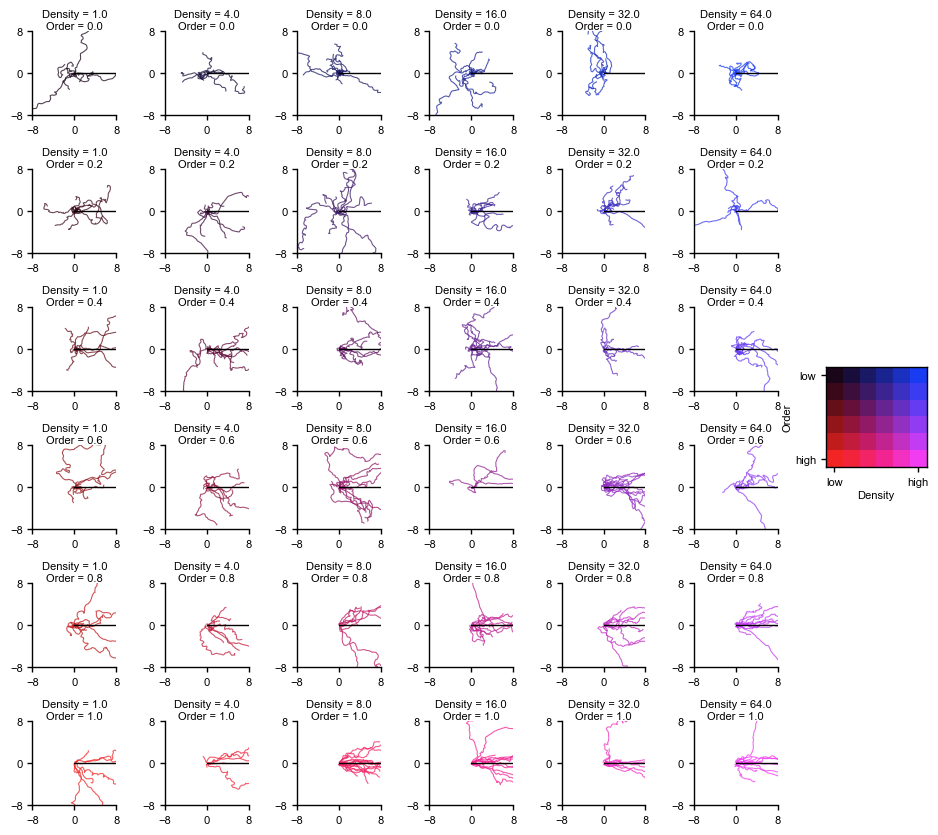

In [8]:
# XY trajectories for every locust per (order, density) condition (colored
# by the shared 2D order/density key); the matplotlib "how" lives in the
# sibling plotting script.
plots.plot_trajectory_grid(merged_df,
                           save_path="figures/locust/trajectories_order_by_density_grid.pdf")
plt.show()

Saved figure to: figures/locust/mean_vectors_order_by_density_grid.pdf


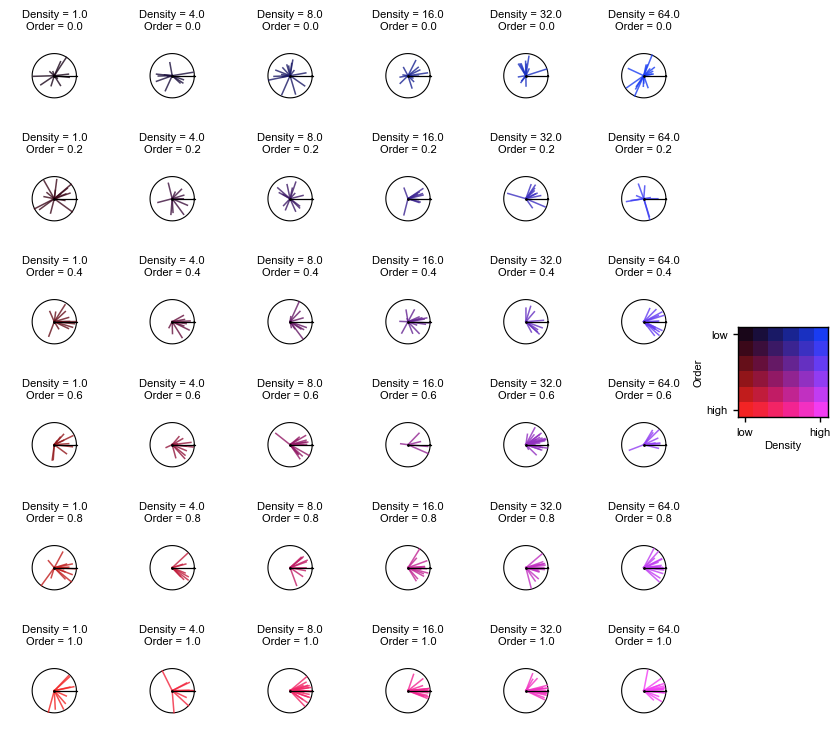

In [9]:
# Mean displacement vector per individual (step-length units, r = 1 = one
# step), one panel per (order, density) condition.
plots.plot_mean_vector_grid(merged_df,
                            save_path="figures/locust/mean_vectors_order_by_density_grid.pdf")
plt.show()

Saved figure to: figures/locust/order_density_trajectories.pdf


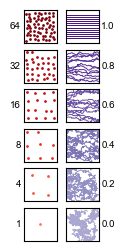

In [10]:
# Synthetic schematic: density dots (left) + order trajectories (right)
# per (order, density) row.
plots.plot_order_density_trajectories(
    save_path="figures/locust/order_density_trajectories.pdf")
plt.show()

Saved figure to: figures/locust/order_density_pairwise_trajectories_only.pdf


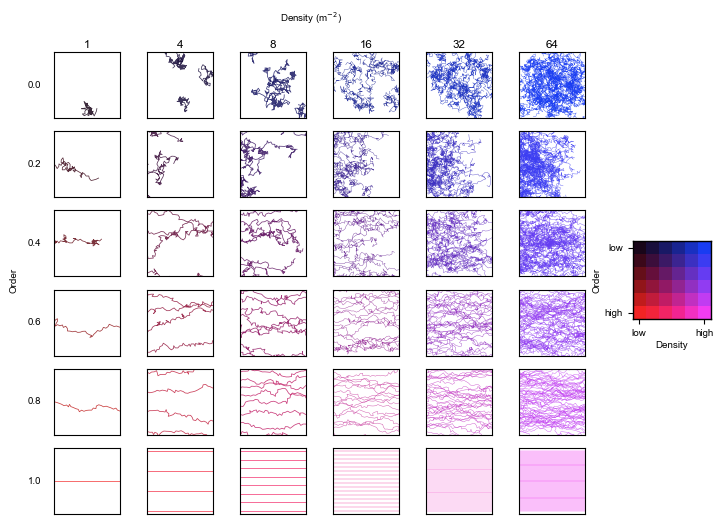

In [11]:
# Synthetic 6x6 order-density grid (n_traj == density), 2D key on the
# right.
plots.plot_order_density_pairwise_trajectories(
    save_path="figures/locust/order_density_pairwise_trajectories_only.pdf")
plt.show()

## Mean step vectors and the modeling table

- **Trajectory plot** (first figure): per-animal re-discretized paths for
  several order–density conditions — higher-order conditions show visibly
  rectilinear, march-aligned paths.
- **Mean-vector plot** (second figure): each animal's mean resultant step
  vector as a ray from the origin inside a unit circle; the ray's angle is the
  animal's mean heading and its length the per-animal mean resultant length.

The modeling table then prepares the heading response (wrapped to
$(-\pi, \pi]$) and the normalized predictors used in all models:
$\tilde{o} = 2\,\mathrm{order} - 1$ and
$\tilde{d} = 2\log_2(\mathrm{density})/\log_2(64) - 1$, both in
$[-1, 1]$, mean-centered at fit time. For **model selection**, each animal is
summarized by the mean resultant direction of its steps — one circular
observation per animal — so the five candidate fixed-effect specifications
(intercept only, order only, density only, additive, interaction) can be
compared with PSIS-LOO at the level of individuals: a fast, individual-level
stand-in for leave-one-individual-out cross-validation.

In [12]:
# One circular observation per animal: the mean resultant step vector per
# (order, density, fname), its angle/magnitude and the wrapped response
# with the scaled predictors (the mean-vector table is folded into the
# screening table; locust_density_posthoc).
screen_df = posthoc.screening_table(merged_df)
screen_df.head()

,order,density,fname,mean_dX,mean_dY,angle_rad,angle_deg,magnitude,y,t_density,t_order
0,0.0,1.0,20220831_1031,-0.227052,-0.006860,-3.111391,-178.269551,0.227156,-3.111391,-1.0,-1.0
1,0.0,1.0,20220831_1631,-0.014402,0.043188,1.892666,108.441761,0.045526,1.892666,-1.0,-1.0
2,0.0,1.0,20220902_1816,0.033093,-0.026388,-0.673137,-38.567935,0.042326,-0.673137,-1.0,-1.0
3,0.0,1.0,20220907_1101,0.153444,0.016937,0.109937,6.298902,0.154376,0.109937,-1.0,-1.0
4,0.0,1.0,20220910_1300,-0.145857,-0.098390,-2.548141,-145.997741,0.175940,-2.548141,-1.0,-1.0


In [13]:
# Individual-level screening model: mu and kappa both depend on the
# interaction of the two predictors (uncentered, no random effects); links
# and priors from unwrap.
formula = bmb.Formula("y ~ t_density * t_order",
                      "kappa ~ t_density * t_order")

priors = {
    # mu parameters (circular)
    "Intercept":  bmb.Prior("VonMises", mu=0.0, kappa=1e-6),                      # U(-pi, pi]
    "t_density": bmb.Prior("Normal", mu=0.0, sigma=0.5*pi),   # slope priors on mu
    "t_order":   bmb.Prior("Normal", mu=0.0, sigma=0.5*pi),
    "t_density:t_order": bmb.Prior("Normal", mu=0.0, sigma=0.5*pi),

    # kappa parameters (on pre-link scale)
    "kappa": {
        "Intercept": bmb.Prior("Normal", mu=inverse_softplus(2.0), sigma=1.0),  # baseline kappa=1
        "t_density": bmb.Prior("Normal", mu=0.0, sigma=1.0),
        "t_order":   bmb.Prior("Normal", mu=0.0, sigma=1.0),
        "t_density:t_order":   bmb.Prior("Normal", mu=0.0, sigma=1.0),
    },
}

model = bmb.Model(
    formula=formula,
    data=screen_df,
    family="vonmises",
    priors=priors,
    link={"mu": circular_modulo, "kappa": softplus},
    center_predictors=False,
)

# Fit
idata = model.fit(draws=1000, chains=4, target_accept=0.9,
                  random_seed=SEED, progressbar=False)

# Store the per-observation log-likelihood (the PyMC 6 / bambi 0.21
# replacement for idata_kwargs={"log_likelihood": True}).
idata = pm.compute_log_likelihood(idata, model=model.backend.model,
                                  progressbar=False)

# Report the divergence count first: R-hat is only meaningful when it is 0.
print("Divergences:", int(idata.sample_stats.diverging.sum()))

Initializing NUTS using jitter+adapt_diag...


Multiprocess sampling (4 chains in 4 jobs)


NUTS: [Intercept, t_density, t_order, t_density:t_order, kappa_Intercept, kappa_t_density, kappa_t_order, kappa_t_density:t_order]


Sampling 4 chains for 1_000 tune and 1_000 draw iterations (4_000 + 4_000 draws total) took 10 seconds.


Divergences: 0


In [14]:
# Posterior summaries; the circular row (the mu intercept) is summarized on
# the circle.
circular_summary(idata, circ_var_names=["Intercept"])

,mean,sd,hdi_3%,hdi_97%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
Intercept,0.045,0.083,-0.114,0.196,0.0016,0.0013,2712,2684,1.00
t_density,0.069,0.117,-0.137845,0.289201,0.0022,0.0019,2719,2779,1.00
t_order,-0.12,0.11,-0.341039,0.070757,0.0022,0.0018,2613,2624,1.00
t_density:t_order,0.146,0.161,-0.16566,0.431243,0.003,0.0025,2940,2862,1.00
kappa_Intercept,1.372,0.17,1.052893,1.68576,0.0028,0.0028,3776,2875,1.00
kappa_t_density,0.802,0.245,0.331862,1.247957,0.0039,0.0046,3995,2750,1.00
kappa_t_order,2.516,0.287,1.980668,3.046085,0.0044,0.0046,4317,3039,1.00
kappa_t_density:t_order,1.01,0.4,0.283733,1.783052,0.0067,0.0065,3526,2807,1.00


Saved figure to: figures/locust/order_density_alignment_screening.pdf


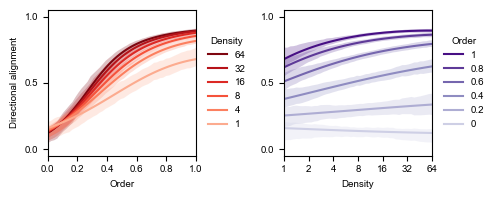

In [15]:
# Screening-fit posterior predictive alignment A(kappa)*cos(mu) on the
# order/density grids (uncentered predictors, 68% HDI, grid of 50),
# computed in locust_density_posthoc.
plots.plot_alignment_screening(idata, merged_df,
                               save_path="figures/locust/order_density_alignment_screening.pdf")
plt.show()

## Model selection (individual-level, PSIS-LOO)

The sweep below fits the five candidate specifications to the
one-observation-per-animal screening table and ranks them by $\Delta$ELPD
relative to the best (next cell):

- **Density $\times$ Order** is the best specification, and **Order** alone
  is within a couple of $\Delta$ELPD units of it (small relative to its SE);
- **Density** alone is the weakest single-predictor model
  ($\Delta$ELPD $\approx$ −76).

This supports the **order-dominant** interpretation: the directional
structure of neighbor motion carries the bulk of the information about the
focal locust's alignment, and visual density adds at most a secondary effect
once order is included. The winning interaction specification is then fitted
to the full step-level data.

In [16]:
# Fit the five candidate specifications to the one-observation-per-animal
# screening table and rank them by pointwise PSIS-LOO delta-ELPD relative
# to the best model (the seeded fits, per-model LOO and the delta-ELPD
# arithmetic live in locust_density_posthoc).
sweep_df = posthoc.model_sweep(screen_df, draws=1000, seed=SEED)


=== Fitting Intercept-only ===


Initializing NUTS using jitter+adapt_diag...


Multiprocess sampling (4 chains in 4 jobs)


NUTS: [Intercept, kappa_Intercept]


Sampling 4 chains for 1_000 tune and 1_000 draw iterations (4_000 + 4_000 draws total) took 2 seconds.


...

Multiprocess sampling (4 chains in 4 jobs)


NUTS: [Intercept, t_density, t_order, t_density:t_order, kappa_Intercept, kappa_t_density, kappa_t_order, kappa_t_density:t_order]


Sampling 4 chains for 1_000 tune and 1_000 draw iterations (4_000 + 4_000 draws total) took 10 seconds.


Divergences: 0



Best model: Density × Order


In [17]:
print(sweep_df[["pretty_name", "elpd", "delta_elpd", "se_delta_elpd",
                "pareto_k_max", "best_model"]].to_string(index=False))

    pretty_name        elpd  delta_elpd  se_delta_elpd  pareto_k_max      best_model
Density × Order -590.814957    0.000000       0.000000      0.349546 Density × Order
Density + Order -593.249415   -2.434459       2.454244      0.261412 Density × Order
          Order -599.675344   -8.860387       5.846474      0.127786 Density × Order
        Density -666.522883  -75.707926      11.227931      0.162298 Density × Order
 Intercept-only -669.259555  -78.444598      11.598301      0.071369 Density × Order


Saved figure to: figures/locust/order_density_model_selection.pdf


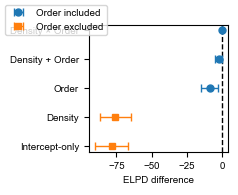

In [18]:
# Delta-ELPD forest: order-included vs order-excluded models.
plots.plot_model_selection(sweep_df,
                           save_path="figures/locust/order_density_model_selection.pdf")
plt.show()

## Final hierarchical fit

The step-level model with a **random intercept for the concentration
($\kappa$) only**:

$$
y_t \sim \mathcal{V}(\mu(\mathbf{x}_i),\ \kappa(\mathbf{x}_i)),
\qquad
\eta_\mu = b_0 + b_d \tilde{d}_i + b_o \tilde{o}_i + b_{do}\,\tilde{d}_i\tilde{o}_i,
\qquad
\eta_\kappa = a_0 + a_d \tilde{d}_i + a_o \tilde{o}_i + a_{do}\,\tilde{d}_i\tilde{o}_i + v_i,
\qquad
v_i \sim \mathcal{N}(0, \sigma^2),
$$

with the `unwrap` circular-modulo link on $\mu$ (linear predictors are
mapped onto the circle at likelihood time) and the softplus link on
$\kappa > 0$. Each animal experienced exactly one order-density
condition, so order and density vary **between animals only** and no
random slope is identifiable. The per-animal *direction* ($\mu$) intercept is
likewise weakly identifiable on this design (10% of animals have five
or fewer steps, and the 440 direction offsets sit on a nearly flat
circular coordinate); with it in the model the sampler failed to mix
($\hat{R}$ up to 1.75 on the $\mu$ fixed effects, zero divergences). The
mean-direction effect is therefore estimated at population level (the
design holds the mean heading at the march direction, $0^\circ$), and
between-animal heterogeneity enters through the $\kappa$ random intercept.
Fit settings: 4 chains $\times$ (2000 tune + 1000 draws).

In [19]:
# Step-level modeling table of the final fit: categorical animal_id,
# wrapped y and the scaled predictors (locust_density_posthoc).
df = posthoc.fit_table(merged_df)

num_samples: 18641


In [20]:
# Pooled-mu component + kappa random intercept per animal.
# Each animal was observed under exactly ONE order-density condition,
# so order/density vary between animals only and no random slope is
# identifiable. Even the per-animal DIRECTION (mu) intercept offsets are
# weakly identifiable on this design (10% of animals have <= 5 steps,
# and the offsets lie on a flat circular coordinate): with them in the
# model the sampler failed to mix (rhat up to 1.75 on the mu fixed
# effects, ESS in the single digits, 0 divergences). The
# mean-direction effect is therefore estimated at population level (the
# design holds the mean heading at the march direction, 0 deg), and
# between-animal heterogeneity enters through the kappa random intercept.
formula = bmb.Formula(
    "y ~ t_density * t_order",
    "kappa ~ t_density * t_order + (1 | animal_id)",
)

priors = {
    # mu parameters
    "Intercept": bmb.Prior("VonMises", mu=0.0, kappa=3.0),
    "t_density": bmb.Prior("Normal", mu=0.0, sigma=0.5*np.pi),
    "t_order":   bmb.Prior("Normal", mu=0.0, sigma=0.5*np.pi),
    "t_density:t_order": bmb.Prior("Normal", mu=0.0, sigma=0.25*np.pi),

    # No mu random intercept: see the comment above the formula.
    # The between-animal direction offsets are weakly identifiable here
    # and including them broke sampling (see Sampling diagnostics).

    # kappa parameters (pre-softplus)
    "kappa": {
        "Intercept": bmb.Prior("Normal", mu=inverse_softplus(2.0), sigma=0.5),
        "t_density": bmb.Prior("Normal", mu=0.0, sigma=0.6),
        "t_order":   bmb.Prior("Normal", mu=0.0, sigma=0.6),
        "t_density:t_order": bmb.Prior("Normal", mu=0.0, sigma=0.4),

        # kappa random intercept
        "1|animal_id": bmb.Prior(
            "Normal", mu=0.0,
            sigma=bmb.Prior("Normal", mu=inverse_softplus(1.0), sigma=0.3, transform=Softplus())
        ),
    },
}

model = bmb.Model(
    formula=formula,
    data=df,
    family="vonmises",
    priors=priors,
    link={"mu": circular_modulo, "kappa": softplus},
    center_predictors=True,
    categorical="animal_id",
    dropna=True,
)
model.build()

print(model)

# ----------------------------
# Fit WITHOUT PyMC's automatic log_likelihood (it breaks w/ transformed RV names)
# ----------------------------
# Optional: seed numpy for any downstream randomness you might add
np.random.seed(SEED)

idata_hierarchical = model.fit(
    draws=1000, tune=2000, chains=4, cores=4,
    target_accept=0.9,
    init="jitter+adapt_diag",
    random_seed=SEED,
    omit_offsets=False,
    progressbar=False,
)

# ----------------------------
# Add pointwise log-likelihood manually for elpd_loo
# ----------------------------
# N.B.: bambi bug, tracked upstream at bambinos/bambi#1084:
# Model.predict(kind="response_params") applies the vonmises *mean* link,
# angle(exp(1j x)), to every component, so its "kappa" is the wrapped
# linear predictor (can be negative) instead of softplus(linear predictor).
# That breaks the log-likelihood below. Temporary fix until the official
# bambi fix ships: read the response parameters straight from the PyMC graph
# with compute_deterministics, which uses each component's actual link.

# Second bambi quirk needed for the call below: with random effects,
# Model.fit(omit_offsets=True) -- the default -- drops the non-centred
# "offset" free RVs (e.g. "kappa_1|animal_id_offset") from the posterior, and
# compute_deterministics reads every free RV by that exact name
# (KeyError: 'kappa_1|animal_id_offset'). omit_offsets=False keeps them.
# Only relevant for random-effects models; plain GLMs are unaffected.
#
# Official (currently broken for the kappa component):
# preds = model.predict(idata_hierarchical, kind="response_params", inplace=False)
# mu    = preds.posterior["mu"]
# kappa = preds.posterior["kappa"]

posthoc.attach_log_likelihood(idata_hierarchical, model, df)

       Formula: y ~ t_density * t_order
                kappa ~ t_density * t_order + (1 | animal_id)
        Family: vonmises
          Link: mu = circular_modulo
                kappa = softplus
  Observations: 18641
        Priors: 
    target = mu
        Common-level effects
            Intercept ~ VonMises(mu: 0.0, kappa: 3.0)
            t_density ~ Normal(mu: 0.0, sigma: 1.5708)
            t_order ~ Normal(mu: 0.0, sigma: 1.5708)
            t_density:t_order ~ Normal(mu: 0.0, sigma: 0.7854)
    target = kappa
        Common-level effects
            kappa_Intercept ~ Normal(mu: 1.8546, sigma: 0.5)
            kappa_t_density ~ Normal(mu: 0.0, sigma: 0.6)
            kappa_t_order ~ Normal(mu: 0.0, sigma: 0.6)
            kappa_t_density:t_order ~ Normal(mu: 0.0, sigma: 0.4)
        
        Group-level effects
            kappa_1|animal_id ~ Normal(mu: 0.0, sigma: Normal(mu: 0.5413, sigma: 0.3, transform:
                log_exp_m1))



Initializing NUTS using jitter+adapt_diag...


Multiprocess sampling (4 chains in 4 jobs)


NUTS: [Intercept, t_density, t_order, t_density:t_order, kappa_Intercept, kappa_t_density, kappa_t_order, kappa_t_density:t_order, kappa_1|animal_id_sigma_log_exp, kappa_1|animal_id_offset]


Sampling 4 chains for 2_000 tune and 1_000 draw iterations (8_000 + 4_000 draws total) took 864 seconds.


response params from PyMC graph OK (kappa all positive)


<xarray.DataTree>
Group: /
├── Group: /posterior
│       Dimensions:                   (chain: 4, draw: 1000, animal_id__factor_dim: 440)
│       Coordinates:
│         * chain                     (chain) int64 32B 0 1 2 3
│         * draw                      (draw) int64 8kB 0 1 2 3 4 ... 995 996 997 998 999
│         * animal_id__factor_dim     (animal_id__factor_dim) <U3 5kB '0' '1' ... '439'
│       Data variables:
│           Intercept                 (chain, draw) float64 32kB -0.0686 ... -0.0558
│           t_density                 (chain, draw) float64 32kB -0.1457 ... -0.1382
│           t_order                   (chain, draw) float64 32kB 0.08756 ... 0.05542
│           t_density:t_order         (chain, draw) float64 32kB 0.1397 ... 0.1521
│           kappa_Intercept           (chain, draw) float64 32kB 0.3498 ... 0.3259
│           kappa_t_density           (chain, draw) float64 32kB 0.341 ... 0.06598
│           kappa_t_order             (chain, draw) float64 32kB 2.343 2.164 ... 2.567
│           kappa_t_density:t_order   (chain, draw) float64 32kB 0.3433 0.237 ... 0.8322
│           kappa_1|animal_id_sigma   (chain, draw) float64 32kB 1.893 1.882 ... 1.983
│           kappa_1|animal_id_offset  (chain, draw, animal_id__factor_dim) float64 14MB ...
│           kappa_1|animal_id         (chain, draw, animal_id__factor_dim) float64 14MB ...
│       Attributes:
│           created_at:                  2026-11-01T17:10:36.093618+00:00
│           creation_library:            ArviZ
│           creation_library_version:    1.3.1
│           creation_library_language:   Python
│           inference_library:           pymc
│           inference_library_version:   6.3.2
│           sample_dims:                 ['chain', 'draw']
│           sampling_time:               863.6842513084412
│           tuning_steps:                2000
│           modeling_interface:          bambi
│           modeling_interface_version:  0.21.0
├── Group: /sample_stats
│       Dimensions:                (chain: 4, draw: 1000)
│       Coordinates:
│         * chain                  (chain) int64 32B 0 1 2 3
│         * draw                   (draw) int64 8kB 0 1 2 3 4 5 ... 995 996 997 998 999
│       Data variables: (12/18)
│           acceptance_rate        (chain, draw) float64 32kB 0.9818 0.8909 ... 0.9111
│           divergences            (chain, draw) int64 32kB 0 0 0 0 0 0 ... 0 0 0 0 0 0
│           step_size_bar          (chain, draw) float64 32kB 0.1726 0.1726 ... 0.1743
│           process_time_diff      (chain, draw) float64 32kB 0.2276 0.2615 ... 0.2217
│           smallest_eigval        (chain, draw) float64 32kB nan nan nan ... nan nan
│           n_steps                (chain, draw) float64 32kB 31.0 31.0 ... 31.0 31.0
│           ...                     ...
│           max_energy_error       (chain, draw) float64 32kB -0.4034 0.2694 ... 0.3325
│           energy_error           (chain, draw) float64 32kB -0.07867 ... -0.06729
│           lp                     (chain, draw) float64 32kB -2.672e+04 ... -2.674e+04
│           index_in_trajectory    (chain, draw) int64 32kB -23 -12 22 -25 ... -26 19 15
│           energy                 (chain, draw) float64 32kB 2.693e+04 ... 2.697e+04
│           tree_depth             (chain, draw) int64 32kB 5 5 5 5 5 5 ... 5 5 5 5 5 5
│       Attributes:
│           created_at:                  2026-11-01T17:10:36.119788+00:00
│           creation_library:            ArviZ
│           creation_library_version:    1.3.1
│           creation_library_language:   Python
│           inference_library:           pymc
│           inference_library_version:   6.3.2
│           sample_dims:                 ['chain', 'draw']
│           sampling_time:               863.6842513084412
│           tuning_steps:                2000
│           modeling_interface:          bambi
│           modeling_interface_version:  0.21.0
├── Group: /observed_data
│       Dimensions:  (__obs__: 18641)
│       Coordina

In [21]:
# PSIS-LOO of the final fit; the per-observation log-likelihood is stored
# under the response's variable name "y" by the fit cell above.
loo = az.loo(idata_hierarchical, var_name="y")
p_eff = float(loo.p)
N = 18641
print("p_loo (effective params):", p_eff)
print("N / p_loo:", N / p_eff)

p_loo (effective params): 224.56325998439505
N / p_loo: 83.01001687139458


/home/jake/.venvs/unwrap-env/lib/python3.12/site-packages/arviz_stats/loo/loo_helper.py:1169: UserWarning: Estimated shape parameter of Pareto distribution is greater than 0.70 for one or more samples. You should consider using a more robust model, this is because importance sampling is less likely to work well if the marginal posterior and LOO posterior are very different. This is more likely to happen with a non-robust model and highly influential observations.
  warnings.warn(


In [22]:
print("fraction k>0.7:", np.mean(loo.pareto_k.values > 0.7))

fraction k>0.7: 0.0021458076283461186


In [23]:
# Posterior summaries of the final fit; the circular row (the mu
# intercept) is summarized on the circle.
summary_df = circular_summary(idata_hierarchical, circ_var_names=["Intercept"])

In [24]:
summary_df

,mean,sd,hdi_3%,hdi_97%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
Intercept,-0.0666,0.0136,-0.091,-0.041,0.0002,0.0002,4508,3503,1.00
t_density,-0.1434,0.0198,-0.179983,-0.106443,0.00028,0.0003,4982,3360,1.00
t_order,0.0727,0.0172,0.039811,0.103821,0.00025,0.00025,4567,3494,1.00
t_density:t_order,0.156,0.0269,0.102581,0.204374,0.0004,0.0004,4605,2951,1.00
kappa_Intercept,0.438,0.111,0.223329,0.638932,0.0039,0.002,814,1363,1.00
kappa_t_density,0.42,0.16,0.143615,0.743918,0.0059,0.003,743,1185,1.00
kappa_t_order,2.331,0.16,2.031026,2.630478,0.0047,0.0025,1147,1776,1.00
kappa_t_density:t_order,0.64,0.218,0.230786,1.04734,0.0059,0.0032,1348,1832,1.01
kappa_1|animal_id_sigma,1.92,0.091,1.744772,2.088164,0.0025,0.0014,1364,1849,1.00
kappa_1|animal_id_offset[0],-1.29,0.58,-2.377429,-0.259863,0.0081,0.011,6459,2658,1.00


In [25]:
summary_df[(summary_df["ess_bulk"]<400) | (summary_df["ess_tail"]<400)]

,mean,sd,hdi_3%,hdi_97%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat


In [26]:
summary_df[(summary_df["r_hat"]>1.01)]

,mean,sd,hdi_3%,hdi_97%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat


## Sampling diagnostics

ESS / $\hat{R}$ tables for the final fit. With the pooled-$\mu$
specification, **all reported parameters pass**: $\hat{R} \le 1.01$ and
ESS well above 400 for the fixed effects (Intercept, `t_density`,
`t_order`, the interaction, and the corresponding `kappa_*` terms) used
for the scientific claims, and for the $\kappa$ random intercept
(aggregate and hyperparameter). The reason the direction component is not
given random effects is that the 440 between-animal direction offsets are
weakly identified under this design (one condition per animal; 10% of
animals have five or fewer steps): including them produced $\hat{R}$ up to
1.75 with zero divergences -- a weakly identified hierarchy, not a
sampling failure -- so they are estimated at population level instead.

## Posterior predictive checks

The final set of figures validates the hierarchical fit with the alignment
statistic and the predictive density at the march direction:

- **Alignment surfaces**: the posterior predictive alignment
  $\mathcal{A}(\mathbf{x})$ as a function of order (one panel per density)
  and of density (one panel per order), with open markers at the observed
  cells from a hierarchical bootstrap of the data (resample animals, then
  steps within animals). Alignment rises with order and levels off once order
  is high; the change across density 1–64 m$^{-2}$ is comparatively small.
- **Predictive density at $0^\circ$**: the posterior density mass the model
  places exactly at the march direction, over order and over density, with a
  dashed uniform reference ($1/2\pi$).
- **Coefficient posteriors**: the fixed-effect posteriors for
  $\mu(\mathbf{x})$ and $\kappa(\mathbf{x})$ (pre-link scale) with 95 %
  HDIs, next to the $\Delta$ELPD comparison.
- **Cell-level PPC** (dots + errorbars at each observed order–density cell):
  open markers are the empirical alignment from the data bootstrap; filled
  markers are the posterior predictive alignment, obtained by simulating the
  same number of steps per animal from the individual-level likelihood
  (fixed effects + that animal's random effects) and applying the identical
  bootstrap to the simulated data.
- **Individual-level PPC** (36 panels, one per order–density condition): the
  per-animal alignment statistic, data (within-individual bootstrap of steps)
  vs model (posterior predictive using each animal's own random effects);
  dashed lines mark zero alignment.

Where the data and model markers and intervals agree across all 36 cells, the
hierarchical von Mises GLM reproduces the main features of the directional
alignment data at both the population and the individual level.

Saved figure to: figures/locust/order_density_alignment.pdf


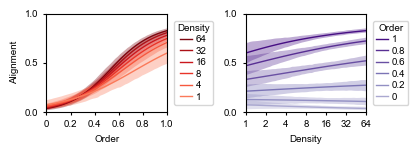

In [27]:
# Posterior predictive alignment of the final fit (training-mean-centered
# predictors, 90% HDI, grid of 50), computed in locust_density_posthoc.
plots.plot_alignment(idata_hierarchical, df,
                     save_path="figures/locust/order_density_alignment.pdf")
plt.show()

Saved figure to: figures/locust/order_density_elpd0.pdf


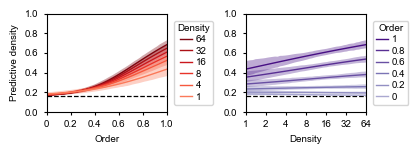

In [28]:
# Posterior predictive density at the march direction (0 deg), computed in
# log space and exponentiated (90% HDI, grid of 50).
plots.plot_elpd0(idata_hierarchical, df,
                 save_path="figures/locust/order_density_elpd0.pdf")
plt.show()

Saved figure to: figures/locust/order_density_polar_pdfs_grid.pdf


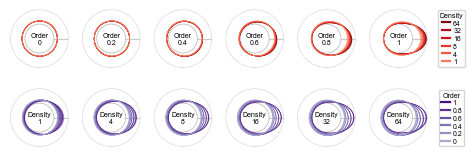

In [29]:
# Per-cell posterior predictive von Mises PDFs (median + 90% HDI band over
# a 900-point circle), per order (top row) and per density (bottom row).
plots.plot_polar_pdfs(idata_hierarchical, df,
                      save_path="figures/locust/order_density_polar_pdfs_grid.pdf")
plt.show()

Saved figure to: figures/locust/order_density_coefficients.pdf


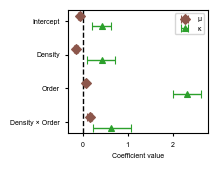

In [30]:
# Fixed-effect coefficient posteriors (mu vs kappa, pre-link scale) with
# 95% HDI error bars; circular for the mu intercept.
plots.plot_coefficients(idata_hierarchical,
                        save_path="figures/locust/order_density_coefficients.pdf")
plt.show()

Saved figure to: figures/locust/order_density_model_selection_and_coefficients.pdf


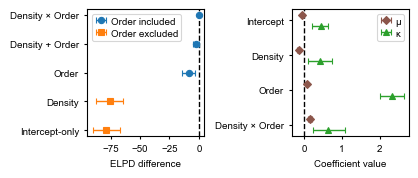

In [31]:
# Combined figure: model comparison (delta ELPD, left) next to the
# coefficient posteriors (mu vs kappa, right).
plots.plot_selection_and_coefficients(sweep_df, idata_hierarchical,
                                      save_path="figures/locust/order_density_model_selection_and_coefficients.pdf")
plt.show()

/tmp/opencode/wt-unified/notebooks/locust_density_plots.py:1243: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


Saved figure to: figures/locust/order_density_alignment_ppc_bootstrap.pdf


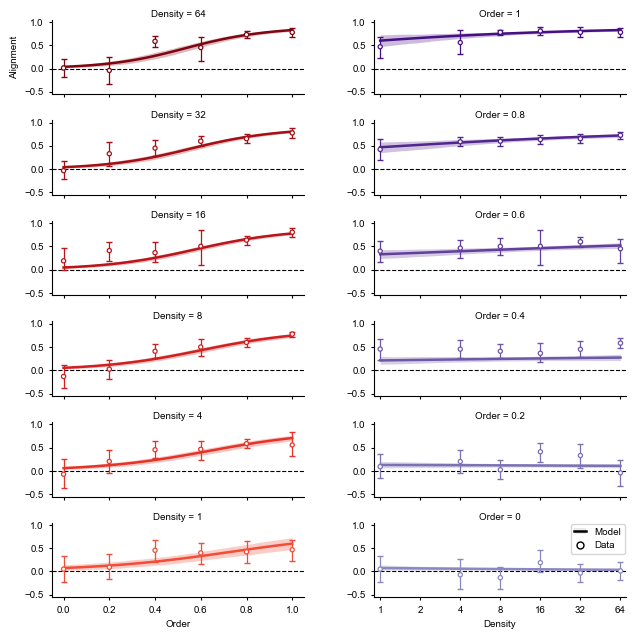

In [32]:
# Final-fit alignment curves (95% HDI, grid of 80) with the hierarchical
# data bootstrap (resample animals, then steps within animals; B=1000) at
# the observed order-density cells (open markers).
plots.plot_alignment_ppc_bootstrap(idata_hierarchical, df,
                                   save_path="figures/locust/order_density_alignment_ppc_bootstrap.pdf")
plt.show()

/tmp/opencode/wt-unified/notebooks/locust_density_plots.py:1393: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


Saved figure to: figures/locust/order_density_cell_ppc_dots.pdf


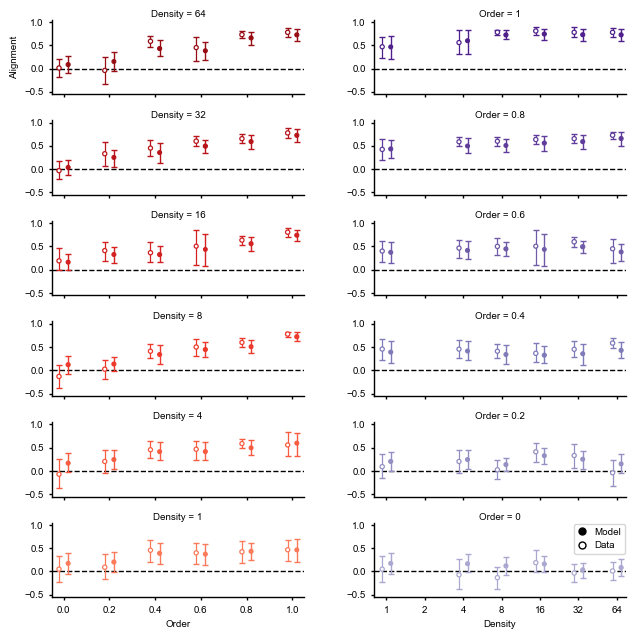

In [33]:
# Cell-level alignment: data bootstrap (open markers, B=1000) vs the
# posterior predictive (filled markers; simulate the same number of steps
# per animal from the individual-level likelihood, B=600) at each observed
# order-density cell.
plots.plot_cell_ppc_dots(idata_hierarchical, df,
                         save_path="figures/locust/order_density_cell_ppc_dots.pdf")
plt.show()

[OK] posterior draws S=4000, animals=440
[OK] mu_re shape=(4000, 440) kappa_re shape=(4000, 440)


Saved figure to: figures/locust/order_density_individual_cell_ppc.pdf


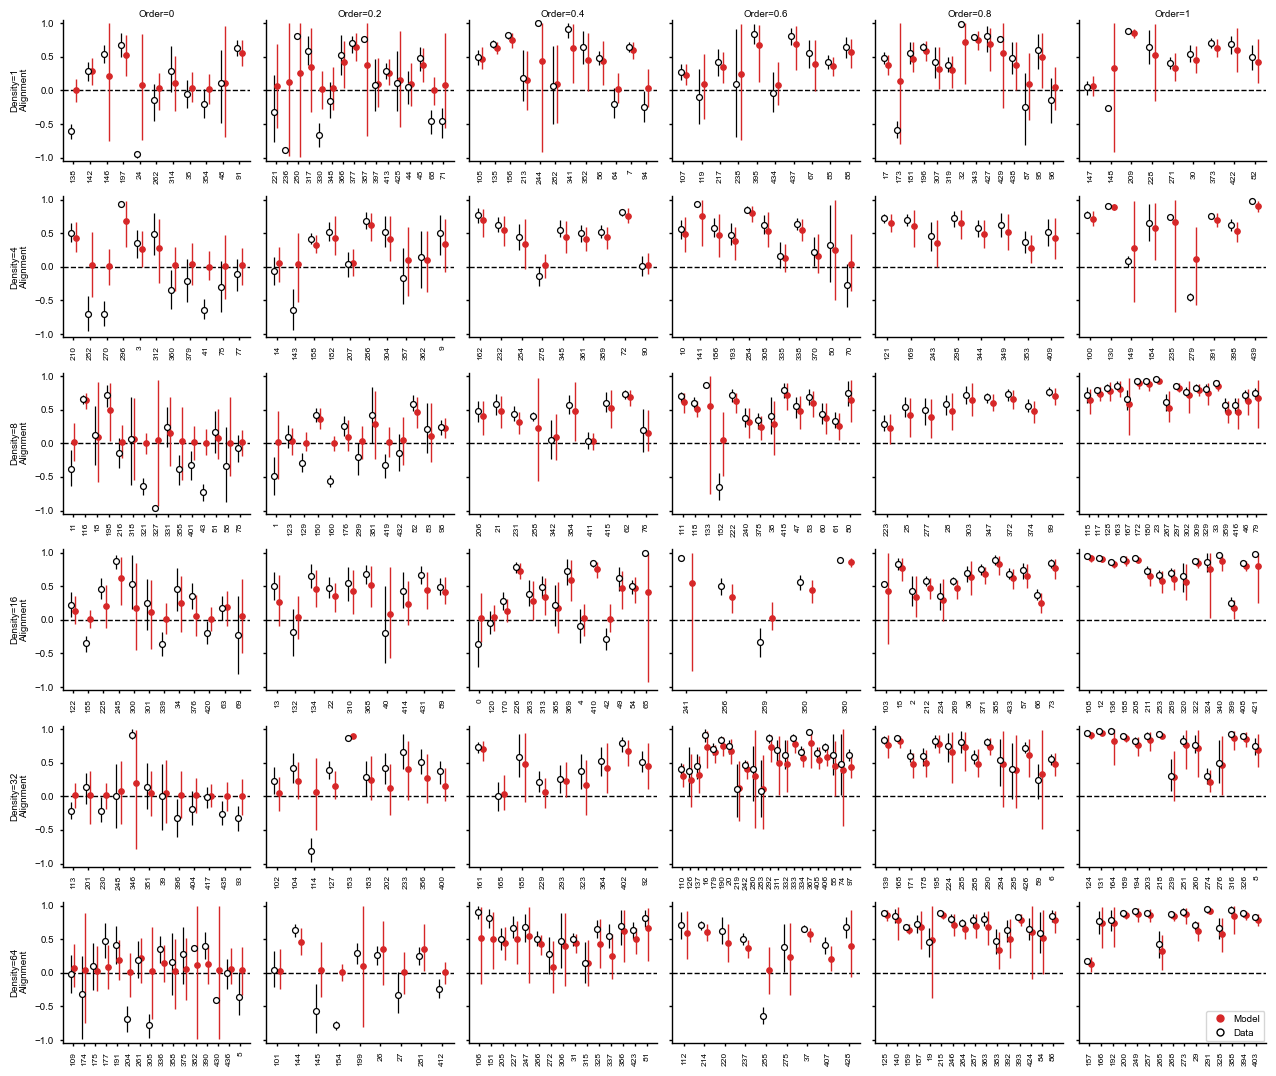

In [34]:
# Individual-level PPC (36 panels, one per order-density condition):
# per-animal alignment, within-animal bootstrap of the data (open markers,
# B=800) vs the individual-level posterior predictive (filled markers,
# 400 posterior predicts) with 95% HDIs.
plots.plot_individual_ppc(idata_hierarchical, df,
                          save_path="figures/locust/order_density_individual_cell_ppc.pdf")
plt.show()